# Swiggy Sales Anlysis

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# importing the dataset

In [18]:
df = pd.read_excel('swiggy_data.xlsx')

In [19]:
# !pip install openpyxl # ye instal nhi thaa to error aa raha tha q ki pandas every tupes ke data ko read nhi kar pata h

In [20]:
df.head()

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
0,Karnataka,Bengaluru,2025-06-29,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0
1,Karnataka,Bengaluru,2025-04-03,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25
2,Karnataka,Bengaluru,2025-01-15,Srinidhi Sagar Deluxe,Kengeri,Recommended,Chow Chow Bath,117.0,4.7,48
3,Karnataka,Bengaluru,2025-04-17,Srinidhi Sagar Deluxe,Kengeri,Recommended,Kesari Bath,65.0,4.6,65
4,Karnataka,Bengaluru,2025-03-13,Srinidhi Sagar Deluxe,Kengeri,Recommended,Mix Raitha,130.0,4.0,0


### Metadata

In [21]:
print('No of Rows:',df.shape[0])

No of Rows: 197430


In [22]:
print('No of Fields:',df.shape[1])

No of Fields: 10


In [23]:
df.info

<bound method DataFrame.info of             State       City Order Date           Restaurant Name  \
0       Karnataka  Bengaluru 2025-06-29  Anand Sweets & Savouries   
1       Karnataka  Bengaluru 2025-04-03     Srinidhi Sagar Deluxe   
2       Karnataka  Bengaluru 2025-01-15     Srinidhi Sagar Deluxe   
3       Karnataka  Bengaluru 2025-04-17     Srinidhi Sagar Deluxe   
4       Karnataka  Bengaluru 2025-03-13     Srinidhi Sagar Deluxe   
...           ...        ...        ...                       ...   
197425     Sikkim    Gangtok 2025-01-25            Mama's Kitchen   
197426     Sikkim    Gangtok 2025-07-02            Mama's Kitchen   
197427     Sikkim    Gangtok 2025-03-25            Mama's Kitchen   
197428     Sikkim    Gangtok 2025-03-26            Mama's Kitchen   
197429     Sikkim    Gangtok 2025-03-27            Mama's Kitchen   

                    Location     Category  \
0       Rajarajeshwari Nagar        Snack   
1                    Kengeri  Recommended   
2   

## Datatypes

In [24]:
df.dtypes

State                         str
City                          str
Order Date         datetime64[us]
Restaurant Name               str
Location                      str
Category                      str
Dish Name                     str
Price (INR)               float64
Rating                    float64
Rating Count                int64
dtype: object

In [25]:
df.describe()

,Order Date,Price (INR),Rating,Rating Count
count,197430,197430.000000,197430.000000,197430.000000
mean,2025-05-01 19:41:20.996809,268.512920,4.341582,28.321805
min,2025-01-01 00:00:00,0.950000,1.500000,0.000000
25%,2025-03-01 00:00:00,139.000000,4.300000,0.000000
50%,2025-05-02 00:00:00,229.000000,4.400000,2.000000
75%,2025-07-01 00:00:00,329.000000,4.500000,15.000000
max,2025-08-31 00:00:00,8000.000000,5.000000,999.000000
std,NaN,219.338363,0.422585,87.542593


# KPI's

### Total sales

In [26]:
total_sales = df['Price (INR)'].sum()
print('Total Sales (INR):', total_sales)

Total Sales (INR): 53012505.769999996


## Averaj Rating

In [27]:
average_rating = df['Rating'].mean()
print('Average Rating:',round(average_rating,2))

Average Rating: 4.34


## Average Orser Value

In [28]:
avg_order_value = df['Price (INR)'].mean()
print('Avg Order Values (INR):',round(avg_order_value,2))


Avg Order Values (INR): 268.51


## Rating Counts

In [29]:
rating_count = df['Rating Count'].sum()
print('rating counte',round(rating_count,2))

rating counte 5591574


##  Avg order value

In [30]:
averag_order_value = df['Price (INR)'].mean()
print('avg order value:',round(averag_order_value,2))

avg order value: 268.51


# Total Orders

In [31]:
total_order = len(df)
print('Total_orders:', round(total_order))

Total_orders: 197430


## Charts Desing
monthaly sales trend

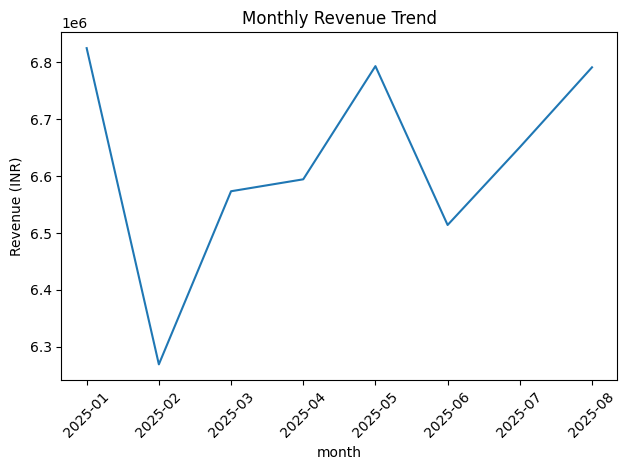

In [34]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['YearMonth'] = df['Order Date'].dt.to_period('M').astype(str)
monthly_revenue = df.groupby('YearMonth')['Price (INR)'].sum().reset_index()
plt.figure()
plt.plot(monthly_revenue['YearMonth'], monthly_revenue['Price (INR)'])
plt.xticks(rotation=45)
plt.xlabel('month')
plt.ylabel('Revenue (INR)')
plt.title('Monthly Revenue Trend')
plt.tight_layout()
plt.show()

## Daily sales Trend

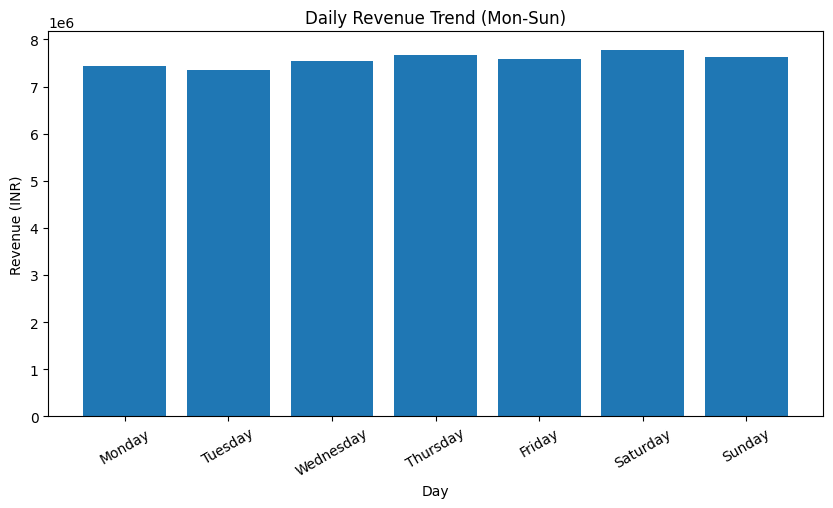

In [38]:
df['DayName'] = pd.to_datetime(df['Order Date']).dt.day_name()

daily_revenue = (
    df.groupby('DayName')['Price (INR)']
    .sum()
    .reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
)
plt.figure(figsize=(10,5))
plt.bar(daily_revenue.index, daily_revenue.values)
plt.title('Daily Revenue Trend (Mon-Sun)')
plt.xlabel('Day')
plt.ylabel('Revenue (INR)')
plt.xticks(rotation=30)
plt.show()

## Total Sales  by Food Type(Veg vs Non-Veg)

In [41]:
non_veg_keyword = [
    'chicken','egg','fish','mutton',
    'prawn','briyani','kabab','kebab',
    'non-veg','non veg'
]
df['Food Category'] = np.where(
    df['Dish Name'].str.lower().str.contains('|'.join(non_veg_keyword), na=False),
    'Non-veg',
    'veg'
)

In [47]:
food_revenue = (
    df.groupby('Food Category')['Price (INR)']
    .sum()
    .reset_index()
)

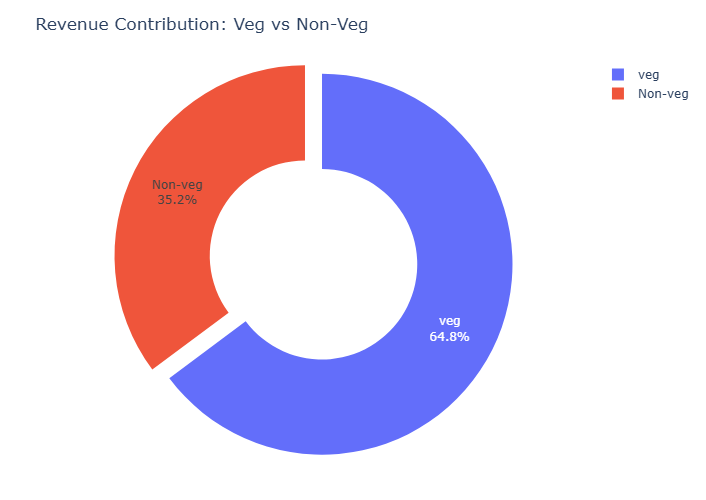

In [50]:
import plotly.express as px

# Clean data
food_revenue = food_revenue.dropna()

fig = px.pie(
    food_revenue,
    values='Price (INR)',
    names='Food Category',
    hole=0.5,
    title='Revenue Contribution: Veg vs Non-Veg'
)

fig.update_traces(
    textinfo='percent+label',
    pull=[0.05]*len(food_revenue)
)

fig.update_layout(
    height=500,
    margin=dict(t=60, b=40, l=40, r=40)
)

fig.show()

## Total Sales by State

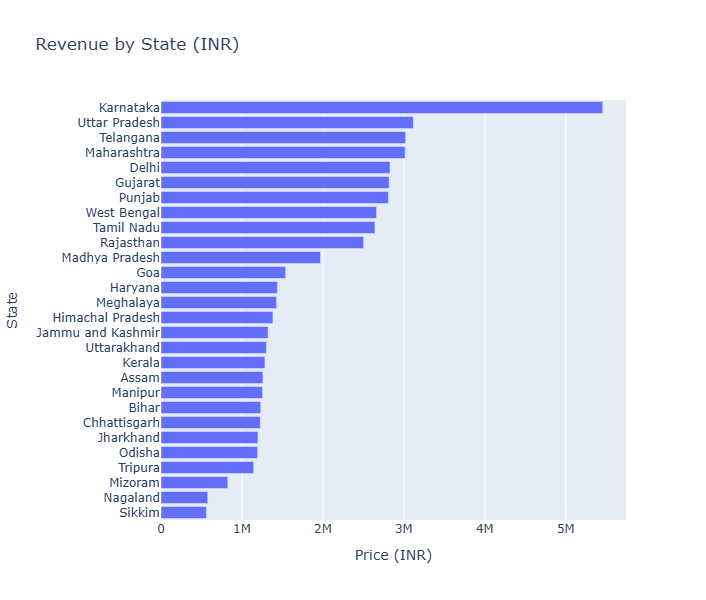

In [52]:
fig = px.bar(
    df.groupby('State',as_index=False)['Price (INR)'].sum()
    .sort_values('Price (INR)',ascending=False),
    x='Price (INR)',
    y='State',
    orientation='h',
    title='Revenue by State (INR)'
)
fig.update_layout(height=600,yaxis=dict(autorange='reversed'))
fig.show()

## Quarterly Performance Summary

In [60]:
df['Order_Date'] = pd.to_datetime(df['Order Date'])
df['Quarter'] = df['Order_Date'].dt.to_period('Q').astype(str)
quarterly_summary = (
    df.groupby('Quarter',as_index=False)
    .agg(
        Total_Sales=('Price (INR)','sum'),
        Avg_Rating=('Rating','mean'),
        Total_Orders=('Order_Date','count')
       )
        .sort_values('Quarter')
)
quarterly_summary['Total_Sales'] = quarterly_summary['Total_Sales'].round(0)
quarterly_summary['Avg_Rating'] = quarterly_summary['Avg_Rating'].round(2)

quarterly_summary

,Quarter,Total_Sales,Avg_Rating,Total_Orders
0,2025Q1,19667822.0,4.34,73096
1,2025Q2,19902257.0,4.34,74163
2,2025Q3,13442427.0,4.34,50171


## Top 5 Cityes by Sales

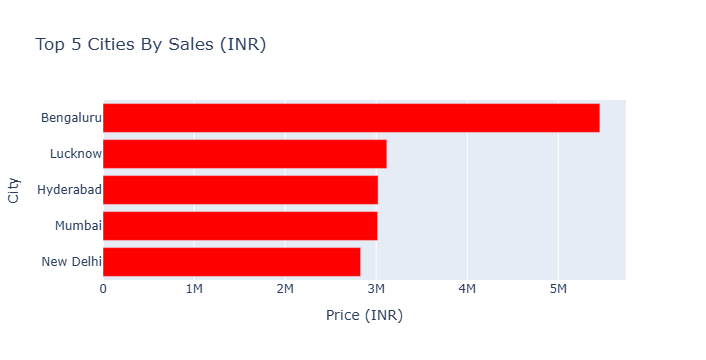

In [65]:
top_5_cities = (
    df.groupby('City')['Price (INR)']
    .sum()
    .nlargest(5)
    .sort_values()
    .reset_index()
)
fig = px.bar(
    top_5_cities,
    x='Price (INR)',
    y='City',
    orientation='h',
    title='Top 5 Cities By Sales (INR)',
    color_discrete_sequence=['red']
)
fig.show()

## Weekly Trends Anlysis

In [71]:
import pandas as pd

# Convert date
df['Order Date'] = pd.to_datetime(df['Order Date'])

# Create Week column
df['Week'] = df['Order Date'].dt.to_period('W').apply(lambda r: r.start_time)

# Create weekly_sales dataframe
weekly_sales = df.groupby('Week')['Price (INR)'].sum().reset_index()

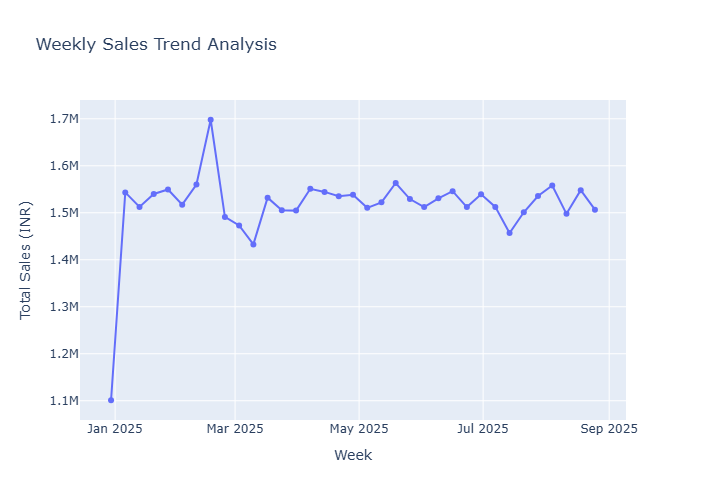

In [72]:
import plotly.express as px

fig = px.line(
    weekly_sales,
    x='Week',
    y='Price (INR)',
    title='Weekly Sales Trend Analysis',
    markers=True
)

fig.update_layout(
    xaxis_title='Week',
    yaxis_title='Total Sales (INR)',
    height=500
)

fig.show()

In [73]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = 'browser'  # force open in browser

# Clean data
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df = df.dropna(subset=['Order Date', 'Price (INR)'])

# Weekly grouping
df['Week'] = df['Order Date'].dt.to_period('W').apply(lambda r: r.start_time)

weekly_sales = df.groupby('Week')['Price (INR)'].sum().reset_index()

print(weekly_sales.head())  # debug

# Plot
fig = px.line(
    weekly_sales,
    x='Week',
    y='Price (INR)',
    title='Weekly Sales Trend Analysis',
    markers=True
)

fig.show()

        Week  Price (INR)
0 2024-12-30   1101057.42
1 2025-01-06   1543434.40
2 2025-01-13   1512362.20
3 2025-01-20   1540131.11
4 2025-01-27   1549636.81
